In [1]:
!pip -q install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

# Load dataset
dataset = fetch_ucirepo(id=601)

X = dataset.data.features
y = dataset.data.targets["Machine failure"]

# Select only the six approved input features
feature_columns = [
    "Type",
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

X = X[feature_columns]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 6)
Testing features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

In [5]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [6]:
models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1 Score,PR-AUC
0,Dummy Classifier,0.0000,0.0000,0.0000,0.0339
1,Logistic Regression,0.1374,0.8044,0.2346,0.4409
2,Random Forest,0.8887,0.3803,0.5312,0.7541


In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    f1_score
)

# Generate out-of-fold probabilities for Random Forest
rf_model = models["Random Forest"]

oof_probabilities = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

# Calculate F1 for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the best F1
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Precision:", round(precision[best_index], 4))
print("Recall:", round(recall[best_index], 4))
print("F1 Score:", round(f1_scores[best_index], 4))

Best threshold: 0.2667
Precision: 0.696
Recall: 0.7011
F1 Score: 0.6985


Final Threshold: 0.2667

Precision: 0.7273
Recall: 0.7059
F1 Score: 0.7164
PR-AUC: 0.7768
ROC-AUC: 0.9634

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1932
     Failure       0.73      0.71      0.72        68

    accuracy                           0.98      2000
   macro avg       0.86      0.85      0.85      2000
weighted avg       0.98      0.98      0.98      2000



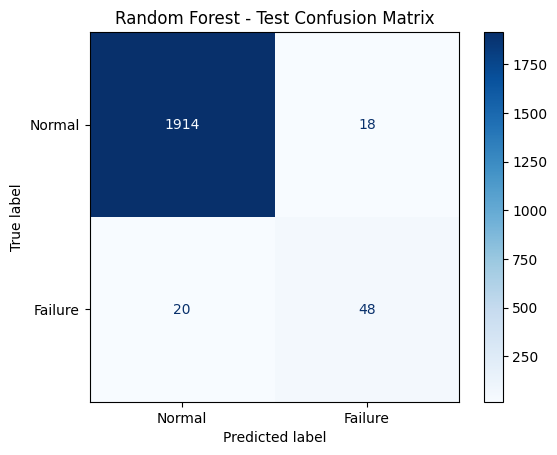

In [9]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Train the selected model on all training data
final_model = models["Random Forest"]

final_model.fit(X_train, y_train)

# Predict failure probabilities on test data
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = best_threshold

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Evaluation
print("Final Threshold:", round(final_threshold, 4))

print("\nPrecision:", round(
    precision_score(y_test, test_predictions), 4
))

print("Recall:", round(
    recall_score(y_test, test_predictions), 4
))

print("F1 Score:", round(
    f1_score(y_test, test_predictions), 4
))

print("PR-AUC:", round(
    average_precision_score(y_test, test_probabilities), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Normal", "Failure"]
))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Failure"]
)

display.plot(cmap="Blues")
plt.title("Random Forest - Test Confusion Matrix")
plt.show()

In [10]:
import joblib
import os

# Create models directory
os.makedirs("models", exist_ok=True)

# Save model, threshold and feature information together
model_artifact = {
    "model": final_model,
    "threshold": float(final_threshold),
    "feature_columns": feature_columns,
    "model_name": "Random Forest",
    "dataset": "UCI AI4I 2020 Predictive Maintenance"
}

joblib.dump(
    model_artifact,
    "models/machineguard_model.joblib"
)

print("Model saved successfully!")
print("File size:",
      round(os.path.getsize("models/machineguard_model.joblib") / 1024, 2),
      "KB")

Model saved successfully!
File size: 10967.33 KB


In [11]:
loaded_artifact = joblib.load(
    "models/machineguard_model.joblib"
)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

sample = X_test.iloc[[0]]

probability = loaded_model.predict_proba(sample)[0, 1]

prediction = int(probability >= loaded_threshold)

print("Failure probability:", round(probability, 4))
print("Threshold:", loaded_threshold)
print("Predicted class:", prediction)

Failure probability: 0.1367
Threshold: 0.26666666666666666
Predicted class: 0
